In [20]:
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet, diagnostics
from prophet.diagnostics import cross_validation

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Load and preprocess the dataset
def load_and_preprocess_data(filepath):
    df = pd.read_csv(filepath, delimiter=',')
    df['Time'] = pd.to_datetime(df['Time'])
    df.set_index('Time', inplace=True)
    df.sort_index(inplace=True)
    df['day_of_year'] = df.index.dayofyear
    df['weekday'] = df.index.weekday
    df['hour'] = df.index.hour
    return df

# Extract holiday dates
def get_holidays(df):
    holidays_df = df[df['is_holiday'] == 1]
    holiday_dates = holidays_df.index
    return pd.DataFrame({
        'holiday': 'finnishholidays',
        'ds': pd.to_datetime(holiday_dates),
    })

# Split data into training and test sets
def split_data(df, end_date):
    train_data = df[df.index < end_date]
    test_data = df[df.index >= end_date]
    return train_data, test_data

# Prepare data for Prophet
def prepare_prophet_data(df):
    return df.reset_index().rename(columns={'Time': 'ds', 'Parkings': 'y'})

# Initialize and fit the Prophet model
# Changepoint, seasonality and holiday prior scales are parameters that can be tuned to fit the model to the data
def fit_prophet_model(train_data, holidays_df, exogenous_features):
    prophet_model = Prophet(
        holidays=holidays_df,
        daily_seasonality=True,
        changepoint_prior_scale=0.014,
        seasonality_prior_scale=1.0,
        holidays_prior_scale=60.0
    )
    for feature in exogenous_features:
        prophet_model.add_regressor(feature)
    prophet_model.fit(train_data)
    return prophet_model

# Make predictions with Prophet
def make_predictions(prophet_model, test_data, exogenous_features):
    future = prophet_model.make_future_dataframe(periods=len(test_data), freq='15min')
    for feature in exogenous_features:
        future[feature] = future['ds'].dt.__getattribute__(feature)
    forecast = prophet_model.predict(future)
    forecast['yhat'] = forecast['yhat'].apply(lambda x: max(x, 0))
    return forecast.set_index('ds')['yhat'][-len(test_data):]

# Calculate error metrics
def calculate_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

# Plot the results
def plot_results(train_data, test_data, predictions):
    plt.figure(figsize=(12, 6))
    plt.plot(train_data.index, train_data['Parkings'], label='Actual data', color='orange')
    plt.plot(test_data.index, test_data['Parkings'], color='orange')
    plt.plot(test_data.index, predictions, label='Predicted values', color='green')
    plt.xlabel('Time')
    plt.ylabel('Parking Value')
    plt.title('Prophet Parking Prediction')
    plt.legend()
    plt.show()

  
# Perform diagnostics
def perform_diagnostics(prophet_model, train_data):
    df_cv = diagnostics.cross_validation(
        prophet_model, 
        initial='30 days',  # Adjust initial period to fit within your data range
        period='15 days',   # Adjust period to fit within your data range
        horizon='15 days'   # Adjust horizon to fit within your data range
    )
    df_p = diagnostics.performance_metrics(df_cv)
    print(df_p.head())
    
    # Manual plotting of cross-validation metrics
    metrics = ['mse', 'rmse', 'mae', 'mape', 'coverage']
    for metric in metrics:
        plt.figure(figsize=(10, 6))
        plt.plot(df_p['horizon'], df_p[metric], marker='o', linestyle='-')
        plt.xlabel('Horizon')
        plt.ylabel(metric.upper())
        plt.title(f'{metric.upper()} over Horizon')
        plt.grid(True)
        plt.show()


13:32:47 - cmdstanpy - INFO - Chain [1] start processing
13:32:47 - cmdstanpy - INFO - Chain [1] done processing


Prophet MAE: 98.75154527300361, RMSE: 158.4816011587044


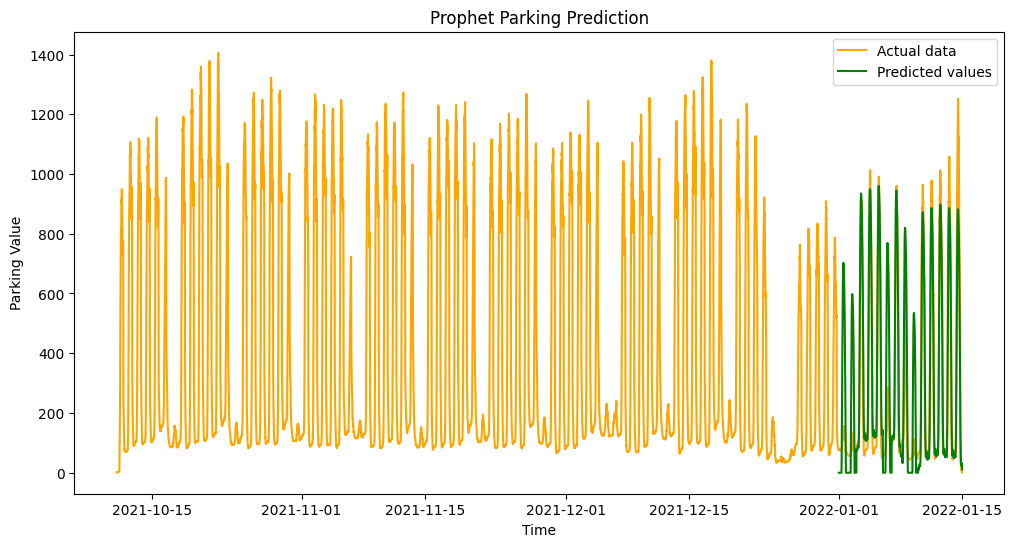

In [21]:
# Main script
if __name__ == "__main__":
    filepath = '../preprocess/parking_time_series_with_features_15min.csv'
    df = load_and_preprocess_data(filepath)
    holidays_df = get_holidays(df)
    end_date = pd.to_datetime('2022-01-01')
    train_data, test_data = split_data(df, end_date)
    train_prophet = prepare_prophet_data(train_data)
    test_prophet = prepare_prophet_data(test_data)
    exogenous_features = ["day_of_year", "weekday", "hour"]
    prophet_model = fit_prophet_model(train_prophet, holidays_df, exogenous_features)
    prophet_pred = make_predictions(prophet_model, test_data, exogenous_features)
    mae_prophet, rmse_prophet = calculate_metrics(test_data['Parkings'], prophet_pred)
    print(f'Prophet MAE: {mae_prophet}, RMSE: {rmse_prophet}')
    plot_results(train_data, test_data, prophet_pred)
    #perform_diagnostics(prophet_model, train_prophet)



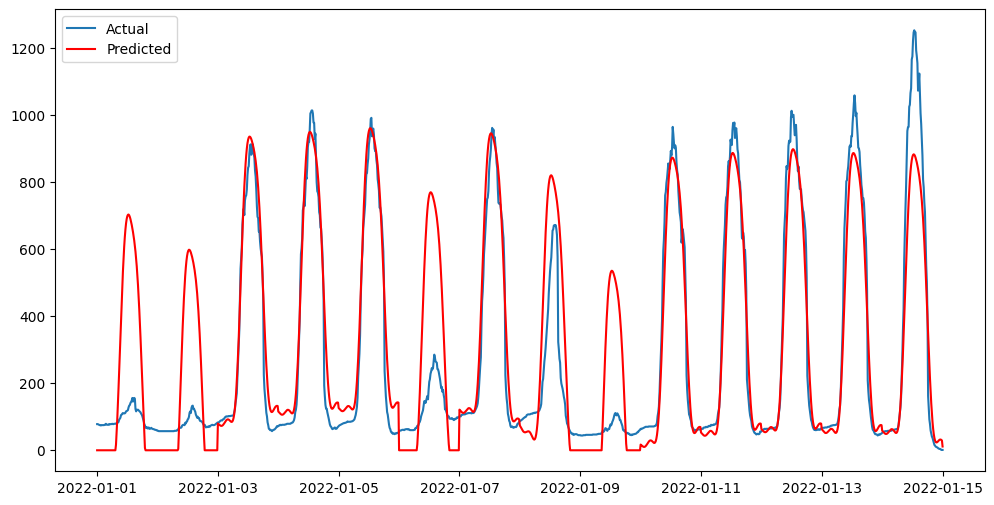

In [22]:
# Plot only the predicted part vs actual values in the test set
plt.figure(figsize=(12, 6))
plt.plot(test_data.index, test_data['Parkings'], label='Actual')
plt.plot(test_data.index, prophet_pred, label='Predicted', color='red')
plt.legend()
plt.show()

In [23]:
from prophet.diagnostics import cross_validation, performance_metrics

# Perform cross-validation
df_cv = cross_validation(prophet_model, initial='30 days', period='14 days', horizon='7 days')

# Calculate performance metrics
df_p = performance_metrics(df_cv)
print(df_p.head())


  0%|          | 0/4 [00:00<?, ?it/s]13:32:48 - cmdstanpy - INFO - Chain [1] start processing
13:32:49 - cmdstanpy - INFO - Chain [1] done processing
 25%|██▌       | 1/4 [00:00<00:01,  2.56it/s]13:32:49 - cmdstanpy - INFO - Chain [1] start processing
13:32:49 - cmdstanpy - INFO - Chain [1] done processing
 50%|█████     | 2/4 [00:00<00:00,  2.05it/s]13:32:50 - cmdstanpy - INFO - Chain [1] start processing
13:32:50 - cmdstanpy - INFO - Chain [1] done processing
 75%|███████▌  | 3/4 [00:01<00:00,  1.79it/s]13:32:50 - cmdstanpy - INFO - Chain [1] start processing
13:32:50 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 4/4 [00:02<00:00,  1.72it/s]

          horizon           mse        rmse         mae      mape     mdape  \
0 0 days 16:45:00  53377.725627  231.036200  163.403745  2.048954  0.399505   
1 0 days 17:00:00  54538.711576  233.535247  166.966794  2.076619  0.406216   
2 0 days 17:15:00  55441.124142  235.459390  170.007843  2.099614  0.421760   
3 0 days 17:30:00  56134.431071  236.927059  172.572076  2.117390  0.434727   
4 0 days 17:45:00  56582.229622  237.870195  174.479667  2.130074  0.437575   

      smape  coverage  
0  0.693455  0.746269  
1  0.696599  0.731343  
2  0.698946  0.720149  
3  0.700510  0.708955  
4  0.700821  0.705224  
